# SVM From Scratch - Gradient Descent + Soft Margin
Implement a Support Vector Machine (SVM) classifier from scratch without using scikit-learn, manually computing the optimal hyperplane using gradient descent and handling non-linearly separable data with soft margin techniques.

In [15]:
import numpy as np
import matplotlib.pyplot as plt

In [16]:
rng = np.random.default_rng(42)
n = 200
X = np.vstack([rng.normal([2, 2], 1.8, (n, 2)), rng.normal([-2, -2], 1.8, (n, 2))])
y = np.hstack([np.ones(n), -np.ones(n)])         

idx = rng.permutation(len(X))
split = int(0.8 * len(X))
X_train, y_train = X[idx[:split]], y[idx[:split]]
X_test,  y_test  = X[idx[split:]], y[idx[split:]]
print(X_train.shape, X_test.shape)

(320, 2) (80, 2)


In [17]:
class SVM:
    def __init__(self, C=1.0, lr=0.01, epochs=1000):
        self.C, self.lr, self.epochs = C, lr, epochs

    def fit(self, X, y):
        self.w, self.b, self.loss = np.zeros(X.shape[1]), 0.0, []
        for _ in range(self.epochs):
            margin = y * (X @ self.w + self.b)
            viol = margin < 1                         
            dw = self.w - self.C * (y[viol] @ X[viol]) / len(y)
            db = -self.C * np.sum(y[viol]) / len(y)
            self.w -= self.lr * dw                  
            self.b -= self.lr * db
            self.loss.append(0.5 * self.w @ self.w + self.C * np.mean(np.maximum(0, 1 - margin)))
        return self

    def predict(self, X):
        return np.where(X @ self.w + self.b >= 0, 1, -1)

def accuracy(y_true, y_pred):
    return np.mean(y_true == y_pred)

In [18]:
svm = SVM(C=1.0, lr=0.01, epochs=1000).fit(X_train, y_train)
print('w =', svm.w, '| b =', round(svm.b, 4))
print('Train accuracy:', accuracy(y_train, svm.predict(X_train)))
print('Test accuracy :', accuracy(y_test, svm.predict(X_test)))

w = [0.29907652 0.2954681 ] | b = 0.0372
Train accuracy: 0.928125
Test accuracy : 0.9375


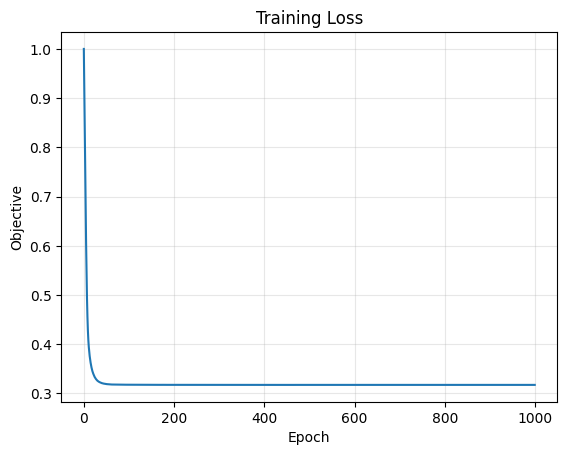

In [19]:
plt.plot(svm.loss)
plt.xlabel('Epoch'); plt.ylabel('Objective'); plt.title('Training Loss')
plt.grid(alpha=0.3); plt.show()

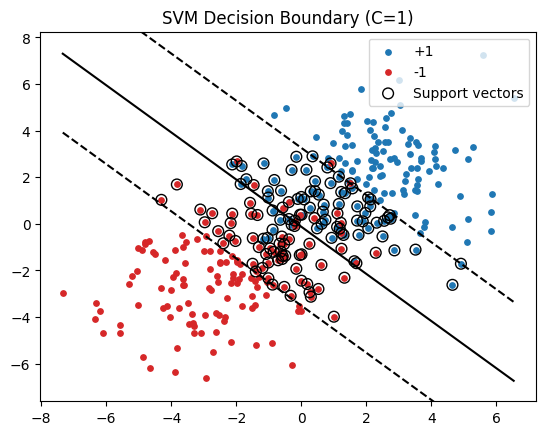

In [20]:
def plot_svm(model, X, y, title):
    plt.scatter(X[y == 1, 0], X[y == 1, 1], c='tab:blue', s=15, label='+1')
    plt.scatter(X[y == -1, 0], X[y == -1, 1], c='tab:red', s=15, label='-1')
    xs = np.linspace(X[:, 0].min(), X[:, 0].max(), 100)
    for offset, style in [(0, 'k-'), (1, 'k--'), (-1, 'k--')]:
        plt.plot(xs, (offset - model.b - model.w[0] * xs) / model.w[1], style) 
    sv = y * (X @ model.w + model.b) <= 1            
    plt.scatter(X[sv, 0], X[sv, 1], s=60, facecolors='none', edgecolors='k', label='Support vectors')
    plt.ylim(X[:, 1].min() - 1, X[:, 1].max() + 1)
    plt.title(title); plt.legend(); plt.show()

plot_svm(svm, X_train, y_train, 'SVM Decision Boundary (C=1)')

In [21]:
print(f"{'C':>7s} {'Margin width':>13s} {'Train acc':>10s} {'Test acc':>9s}")
for C in [0.01, 0.1, 1, 10, 100]:
    m = SVM(C=C, lr=0.01, epochs=2000).fit(X_train, y_train)
    width = 2 / np.linalg.norm(m.w)
    print(f'{C:7} {width:13.3f} {accuracy(y_train, m.predict(X_train)):10.3f} {accuracy(y_test, m.predict(X_test)):9.3f}')

      C  Margin width  Train acc  Test acc
   0.01        69.172      0.931     0.925
    0.1         9.869      0.938     0.938
      1         4.750      0.928     0.938
     10         2.653      0.934     0.938
    100         1.850      0.938     0.938


## Explanation
- **Hard margin** tab kaam karta hai jab data perfectly separable ho. Yahan clusters overlap karte hain, isliye **soft margin** (hinge loss) use kiya.
- **Small C**: margin chauda hota hai, kuch points misclassify hone dete hain (zyada regularization, underfit ka risk).
- **Large C**: margin tang hota hai, misclassification kam karne ki koshish karta hai (overfit ka risk).
- **Support vectors** wo points hain jo margin ke andar ya us par hain (`y*(w.x+b) <= 1`), final hyperplane sirf inhi se decide hota hai.
- Optimizer: batch gradient descent, `w` aur `b` dono ko har epoch me update kiya.